In [78]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "True"

from dotenv import load_dotenv
load_dotenv()


True

In [ ]:
import chunk
import glob
# need to install uv add langchain-community faiss-cpu
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
# to generate and store embeddings need to install uv add langchain-google-genai
from langchain_google_genai import GoogleGenerativeAIEmbeddings

DOCS_DIR = "sample_docs"
INDEX_DIR = "faiss_index"

def load_and_split(docs_dir):
    """Load .txt files and split them into ~500 char chunks with overlap
    """
    chunks = []
    for path in glob.glob(os.path.join(docs_dir, "*.txt")):
        with open(path, "r", encoding="utf-8") as f:
            text = f.read()
        source = os.path.basename(path)
        # Split on double-newline(paragraphs-boundry)
        paragraphs = [p.strip() for p in text.split("\n\n") if p.strip()]
        current = ""
        for para in paragraphs:
            if len(current) + len(para) + 2 <= 500:
                current = (current + "\n\n" + para).strip()
            else:
                if current:
                    chunks.append(Document(page_content=current, metadata={"source": source}))
                current = para
    return chunks

chunks = load_and_split(DOCS_DIR)
print(chunks)
print(f"loaded {len(chunks)} chunks")


[Document(metadata={'source': 'ai_concepts.txt'}, page_content='LangChain is a framework for developing applications powered by large language models ( LLMs).\n\nLangChain simplifies every stage of the LLM application lifecycle:'), Document(metadata={'source': 'ai_concepts.txt'}, page_content='- **Development**: Build your applications using LangChain’s opne-source components and 3rd party integrations. Use LangGraph to build stateful agents with 1st class streaming and human-in-the-loop support.\n- **Productionization: Use LangSmith to inspect, monitor and evaluate your applications, so that you can continuously optimize and deploy with confidence.**\n- **Deployment: Turn your LangGraph apps into production0-ready APIs and Assistants with LangGraph platform**\n- \n- **Overview : Agent = Model + Harness.** LangChain provides `create_agent`: a minimal, highly configurable harness. The harness is everything around the model loop: the prompt, the tools, and any middleware that shapes beha

In [80]:
#embeddings = GoogleGenerativeAIEmbeddings(model="models/embedding-gecko-multilingual-v1")
embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")
vectorstore = FAISS.from_documents(chunks, embeddings)
vectorstore.save_local(INDEX_DIR)
print(f"saved to {INDEX_DIR}")

saved to faiss_index


In [81]:
from pydoc import doc
from langchain_core.tools import tool

@tool
def add(a: int, b: int) -> int:
    """Add two numbers together"""
    return a + b

@tool
def multiply(a: int, b: int) -> int:
    """Multiply two numbers together"""
    return a * b

@tool
def divide(a: int, b: int) -> int:
    """Divide two numbers together"""
    return a / b    

@tool
def search_docs(query: str) -> str:
    """Search the LangChain documentation for the given query
    it contains the information about the LangChain framework, RAG , embeddings, and related topics
    """
    embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")
    vectorstore = FAISS.load_local(INDEX_DIR, embeddings, allow_dangerous_deserialization=True)
    docs = vectorstore.as_retriever(search_kwargs={"k": 3}).invoke(query)
    return "\n\n".join(doc.page_content for doc in docs)


In [82]:
tools = [add, multiply, divide, search_docs]
tools_by_name = {tool.name: tool for tool in tools}

In [83]:
from langchain_groq import ChatGroq

model = ChatGroq(
    model_name="openai/gpt-oss-20b",
    temperature=0,
)

model_with_tools = model.bind_tools(tools)


In [84]:

# Define statue
import operator
import operator
from typing import Annotated
from unittest import result
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage


class MessageState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]
    llm_calls: int

# Define nodes
from langchain_core.messages import SystemMessage, ToolMessage

def llm_call(state: MessageState) -> dict:
    """Call the LLM with the given messages"""
    response = model_with_tools.invoke(
        [SystemMessage(content= ("You are a helpful assistant that can perform arithmetic"
        "and answer querstions about AI/ML concepts"
        "use search_docs for AI/ML questions, math tools for calculations"
        ))]+ state["messages"]
        )
    return {"messages": [response], "llm_calls": state.get("llm_calls", 0) + 1}


def tool_node(state: MessageState) -> dict:
    """Use the tools to answer the question"""
    results = []
    for tool_call in state["messages"][-1].tool_calls:
        t = tools_by_name[tool_call["name"]]
        observation = t.invoke(tool_call["args"])
        results.append(ToolMessage(content=str(observation), tool_call_id=tool_call["id"]))
        return {"messages": results}

from typing import Literal
from langgraph.graph import END

def should_continue(state: MessageState) -> Literal["tool_name", "__end__"]:
    """Decide whether to continue the conversation or end it"""
    last = state["messages"][-1]
    if hasattr(last, "tool_calls") and last.tool_calls:
        return "tool_node"
    return END



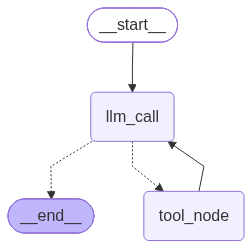

In [85]:
from langgraph.graph import StateGraph, START, END

agent_builder = StateGraph(MessageState)

agent_builder.add_node("llm_call", llm_call)
agent_builder.add_node("tool_node", tool_node)

agent_builder.add_edge(START, "llm_call")
agent_builder.add_conditional_edges(
    "llm_call",
    should_continue,
    ["tool_node", END],
)
agent_builder.add_edge("tool_node", "llm_call")

agent = agent_builder.compile()


from IPython.display import Image, display

display(Image(agent.get_graph().draw_mermaid_png()))

In [90]:
from email import message
from langchain_core.messages import HumanMessage, AIMessage

def run_agent(question: str):
    print(f"Q: {question}")

    result = agent.invoke({"messages": [HumanMessage(content=question)], "llm_calls": 0})
    for msg in result["messages"]:
        if isinstance(msg, AIMessage) and msg.tool_calls:
            for tc in msg.tool_calls:
                print(f" tool: {tc['name']} args: {tc['args']}" )
        elif isinstance(msg, ToolMessage):
            print(f" result: {msg.content[:120]}")

    print(f"A: {result['messages'][-1].content}")
    print()

#run_agent("What is 12 times 10")

run_agent("What is the LangChain")

Q: What is the LangChain
 tool: search_docs args: {'query': 'What is the LangChain'}
 result: LangChain is a framework for developing applications powered by large language models ( LLMs).

LangChain simplifies eve
A: **LangChain** is an open‑source framework that makes it easier to build, test, and deploy applications powered by large language models (LLMs).  

Key points:

| Stage | What LangChain Provides |
|-------|------------------------|
| **Development** | • A library of reusable components (prompts, chains, agents, memory, tools). <br>• Integration with popular LLM providers (OpenAI, Anthropic, Google, etc.). <br>• LangGraph for building stateful, multi‑turn agents with streaming and human‑in‑the‑loop support. |
| **Production** | • LangSmith for monitoring, debugging, and evaluating LLM apps in real time. |
| **Deployment** | • Tools to expose LangGraph apps as APIs or assistants, ready for production use. |

At its core, LangChain treats an *agent* as a **model + harness**: 